## Data Science Portfolio - Game Meta Data Analysis
This notebook explores the Lichess chess game dataset to understand its structure, identify trends in game metadata, and investigate relationships between different game characteristics and outcomes.

The analysis focuses on player ratings, game duration, move counts, opening choices, time controls, and game results. The findings will help identify useful features and potential research questions for subsequent machine learning experiments.

Some of the key questions addressed in this analysis include:
- What is the distribution of game outcomes?
- Does White have a noticeable advantage?
- How does player rating relate to game outcomes?
- Which chess openings are most popular?
- Are some openings more successful than others?
- How long do games typically last?
- Does game start time have any noticeable patterns?

## Dataset Overview

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv('../Resources/games_data.csv', index_col=0)

display(data.head())

print(f"Dataset shape: {data.shape}")
data.info()

,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
id,,,,,,,,,,,,,,,
TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


Dataset shape: (20058, 15)
<class 'pandas.DataFrame'>
Index: 20058 entries, TZJHLljE to N8G2JHGG
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   rated           20058 non-null  bool   
 1   created_at      20058 non-null  float64
 2   last_move_at    20058 non-null  float64
 3   turns           20058 non-null  int64  
 4   victory_status  20058 non-null  str    
 5   winner          20058 non-null  str    
 6   increment_code  20058 non-null  str    
 7   white_id        20058 non-null  str    
 8   white_rating    20058 non-null  int64  
 9   black_id        20058 non-null  str    
 10  black_rating    20058 non-null  int64  
 11  moves           20058 non-null  str    
 12  opening_eco     20058 non-null  str    
 13  opening_name    20058 non-null  str    
 14  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), str(8)
memory usage: 2.3+ MB


In [26]:
print(f"Null values:\n{data.isnull().sum()}")
print(f"Duplicate rows: {data.duplicated().sum()}")
display(data.describe())

Null values:
rated             0
created_at        0
last_move_at      0
turns             0
victory_status    0
winner            0
increment_code    0
white_id          0
white_rating      0
black_id          0
black_rating      0
moves             0
opening_eco       0
opening_name      0
opening_ply       0
dtype: int64
Duplicate rows: 429


,created_at,last_move_at,turns,white_rating,black_rating,opening_ply
count,2.005800e+04,2.005800e+04,20058.000000,20058.000000,20058.000000,20058.000000
mean,1.483617e+12,1.483618e+12,60.465999,1596.631868,1588.831987,4.816981
std,2.850151e+10,2.850140e+10,33.570585,291.253376,291.036126,2.797152
min,1.376772e+12,1.376772e+12,1.000000,784.000000,789.000000,1.000000
25%,1.477548e+12,1.477548e+12,37.000000,1398.000000,1391.000000,3.000000
50%,1.496010e+12,1.496010e+12,55.000000,1567.000000,1562.000000,4.000000
75%,1.503170e+12,1.503170e+12,79.000000,1793.000000,1784.000000,6.000000
max,1.504493e+12,1.504494e+12,349.000000,2700.000000,2723.000000,28.000000


## Game Outcome analysis
We can start by analyzing the distribution of game outcomes in the dataset. The 'victory_status' column indicates whether the game was won by White, won by Black, or ended in a draw. Understanding this distribution can provide insights into the overall competitiveness of the games and whether there is a significant advantage for either player.

We can also look at the distribution of how games ended, whether by checkmate, resignation, timeout, or other means. This can help us understand the nature of the games and how players typically conclude their matches.

winner
white    10001
black     9107
draw       950
Name: count, dtype: int64
winner
white    49.860405
black    45.403330
draw      4.736265
Name: proportion, dtype: float64


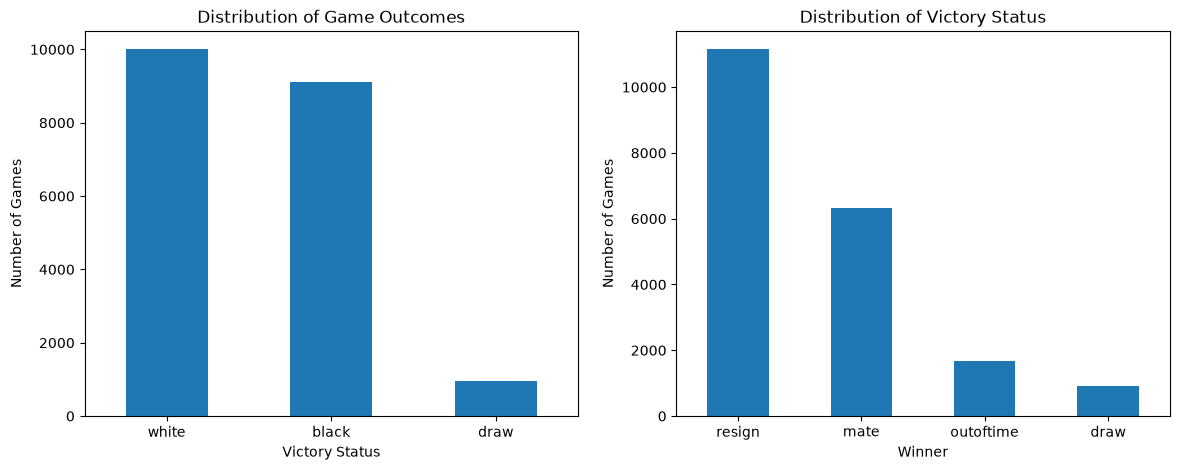

In [27]:
print(data['winner'].value_counts())
print(data['winner'].value_counts(normalize=True) * 100)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

data['winner'].value_counts().plot(
    kind='bar',
    title='Distribution of Game Outcomes',
    ax=ax[0]
)

data['victory_status'].value_counts().plot(
    kind='bar',
    title='Distribution of Victory Status',
    ax=ax[1]

)

ax[0].set_title('Distribution of Game Outcomes')
ax[0].set_xlabel('Victory Status')
ax[0].set_ylabel('Number of Games')
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=0)

ax[1].set_title('Distribution of Victory Status')
ax[1].set_xlabel('Winner')
ax[1].set_ylabel('Number of Games')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)

plt.show()

## Game Length and Move Count Analysis
This data set contains information about the number of turns taken in each game. 
> What is worth noting is that the dataset considers a turn as a **single move** by one player, so a full round of moves (one by White and one by Black) counts as two turns.

Average game length: 60.47
Median game length: 55.00
Shortest game: 1
Longest game: 349


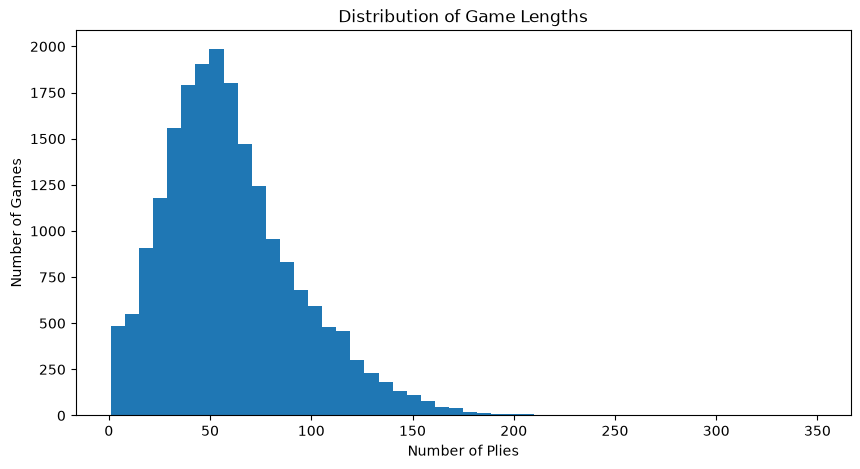

In [28]:
print(f"Average game length: {data['turns'].mean():.2f}")
print(f"Median game length: {data['turns'].median():.2f}")
print(f"Shortest game: {data['turns'].min()}")
print(f"Longest game: {data['turns'].max()}")

plt.figure(figsize=(10, 5))

plt.hist(data['turns'], bins=50)

plt.title('Distribution of Game Lengths')
plt.xlabel('Number of Plies')
plt.ylabel('Number of Games')

plt.show()

## Player Rating Analysis
The dataset includes player ratings for both White and Black players. Analyzing these ratings can help us understand the skill levels of the players involved in the games and how these ratings correlate with game outcomes. 

From plotting the ratings, we can observe that the distribution of player ratings is approximately normal, with most players having ratings around the mean. Interestingly, there is a large spike in the distribution at the 1500 rating mark, which may indicate new accounts that have received the default starting rating.

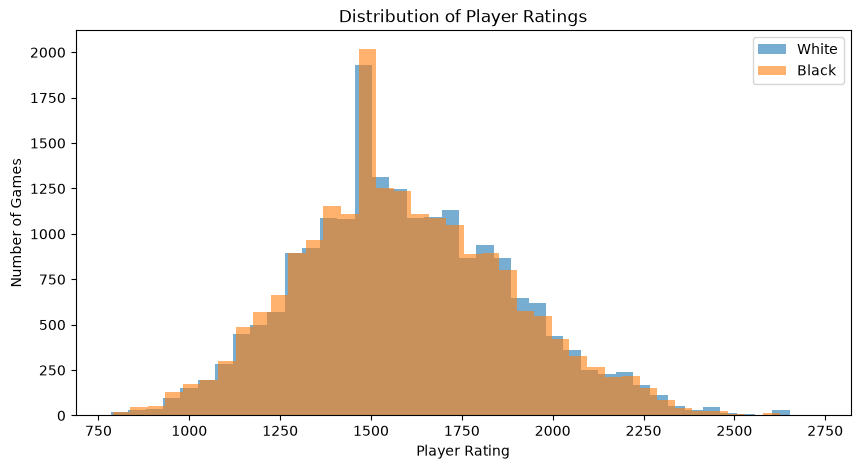

In [29]:
plt.figure(figsize=(10, 5))

plt.hist(data['white_rating'], bins=40, alpha=0.6, label='White')
plt.hist(data['black_rating'], bins=40, alpha=0.6, label='Black')

plt.title('Distribution of Player Ratings')
plt.xlabel('Player Rating')
plt.ylabel('Number of Games')
plt.legend()

plt.show()

## Opening Analysis
The dataset contains information about the chess openings used in each game. It contains columns for the ECO code, opening name, and the number of moves played out of the opening. 

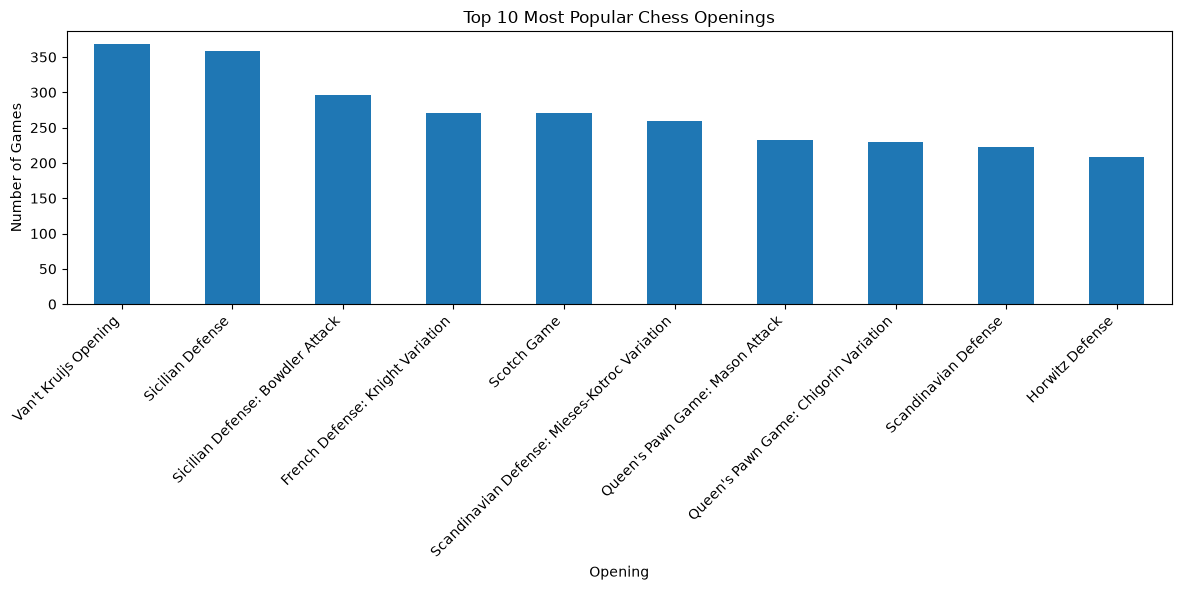

In [40]:
top_openings = data['opening_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))

top_openings.plot(kind='bar')

plt.title('Top 10 Most Popular Chess Openings')
plt.xlabel('Opening')
plt.ylabel('Number of Games')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## Game start time analysis
The dataset includes the start time of each game, along with the time the last move was made. Analyzing the start times can help us identify patterns in when games are played, such as peak hours or days of the week. This information can be useful for understanding player behavior and preferences.

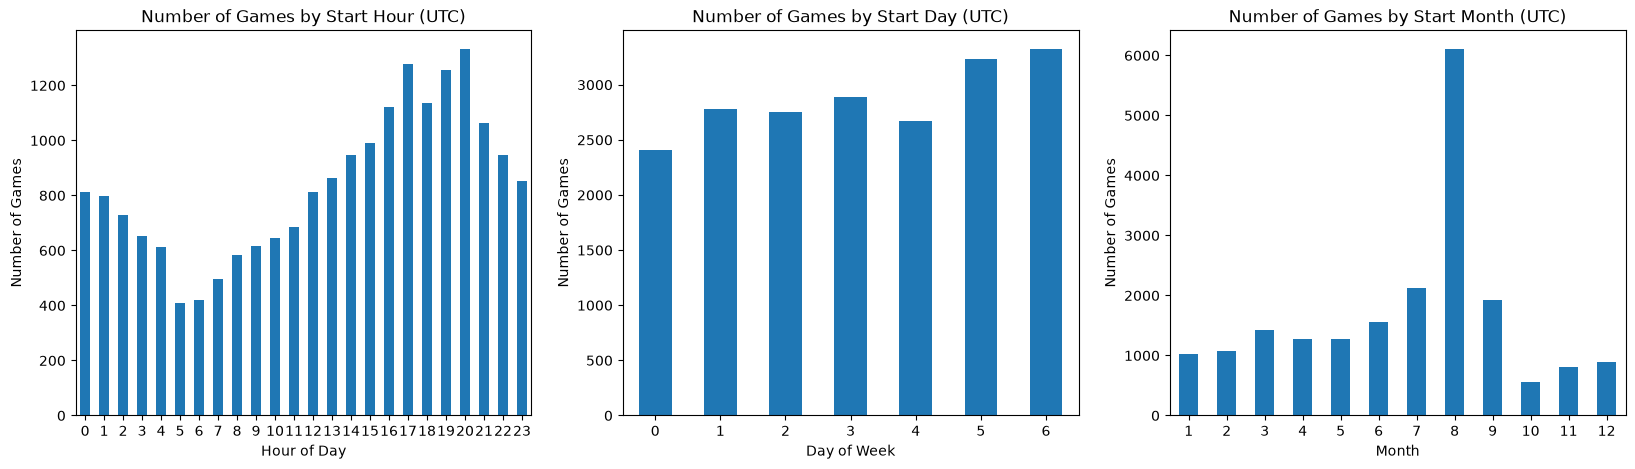

In [62]:
for column in ['created_at', 'last_move_at']:
    data[column] = pd.to_datetime(data[column], unit='ms', utc=True)

data['game_hour'] = data['created_at'].dt.hour
data['game_day'] = data['created_at'].dt.dayofweek
data['game_month'] = data['created_at'].dt.month

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

data['game_hour'].value_counts().sort_index().plot(kind='bar', ax=ax[0])

ax[0].set_title('Number of Games by Start Hour (UTC)')
ax[0].set_xlabel('Hour of Day')
ax[0].set_ylabel('Number of Games')
ax[0].tick_params(axis='x', rotation=0)

data['game_day'].value_counts().sort_index().plot(kind='bar', ax=ax[1])
ax[1].set_title('Number of Games by Start Day (UTC)')
ax[1].set_xlabel('Day of Week')
ax[1].set_ylabel('Number of Games')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)

data['game_month'].value_counts().sort_index().plot(kind='bar', ax=ax[2])
ax[2].set_title('Number of Games by Start Month (UTC)')
ax[2].set_xlabel('Month')
ax[2].set_ylabel('Number of Games')
ax[2].set_xticklabels(ax[2].get_xticklabels(), rotation=0)

plt.show()

## Conclusion
This analysis provides a comprehensive overview of the Lichess chess game dataset, highlighting key trends and relationships between game characteristics and outcomes. The insights gained from this analysis can inform future research questions.
